PLEASE REFER TO APPENDIX ON HOW TO RUN THE CODE, CHANGE THE FILE NAMES ACCORDINGLY IN ORDER FOR THE DATASETS TO BE IMPORTED ON YOUR SYSTEM. YOU CAN LOCATE THE WHEREABOUTS OF THE CSV'S BY CHECKING THE PATHWAY WHERE THE CODE IS TRYING TO IMPORT


USE localized_url function if there's an error with the imports

In [ ]:
import os
def localized_url(url):

    current_dir = os.getcwd().split("statistical-analysis-and-modeling-of-football-data")[0] + "statistical-analysis-and-modeling-of-football-data"
    branch = url.split("statistical-analysis-and-modeling-of-football-data")[1]
    return current_dir + branch

USE localized_url function if there's an error with the imports

In [ ]:
import os
def localized_url(url):

    current_dir = os.getcwd().split("statistical-analysis-and-modeling-of-football-data")[0] + "statistical-analysis-and-modeling-of-football-data"
    branch = url.split("statistical-analysis-and-modeling-of-football-data")[1]
    return current_dir + branch

In [538]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [539]:
player_stats_df=pd.read_csv('Data/understat_fifa_merged_cleaned.csv')

In [540]:
def plot_correlation_matrix(df, threshold=0.8):
    """
    Plots a heatmap showing only strong positive or negative correlations (|r| >= threshold).

    Parameters:
    - df (pd.DataFrame): The input DataFrame.
    - threshold (float): Absolute correlation threshold to display (default: 0.75).
    """
    corr = df.corr()

    # Keep only strong correlations, zero-out weak ones (keeps signs intact)
    filtered_corr = corr.where(corr.abs() >= threshold)

    plt.figure(figsize=(18, 13))
    sns.heatmap(filtered_corr, annot=True, cmap='coolwarm', fmt='.2f', cbar=True,
                mask=filtered_corr.isnull(), square=True, linewidths=0.5, linecolor='gray')
    plt.title(f'Correlation Heatmap (|r| ≥ {threshold})')
    plt.tight_layout()
    plt.show()

In [541]:
stat_columns_list= ['yellow_card', 'red_card','key_passes', 'assists', 'xG','xA', 'xGBuildup', 'xGChain', 'Ball Control', 'Dribbling', 'Slide Tackle',
       'Stand Tackle', 'Aggression', 'Reactions', 'Att. Position',
       'Interceptions', 'Vision', 'Crossing', 'Short Pass', 'Long Pass',
       'Acceleration', 'Stamina', 'Strength', 'Balance', 'Sprint Speed',
       'Agility', 'Jumping', 'Heading', 'Shot Power', 'Finishing',
       'Long Shots', 'Curve', 'FK Acc.', 'Penalties', 'Volleys',
       'GK Positioning', 'GK Handling', 'GK Kicking', 'GK Reflexes', 'GK Diving']

In [542]:
fifa_stat_list= ['Ball Control', 'Dribbling', 'Slide Tackle',
       'Stand Tackle', 'Aggression', 'Reactions', 'Att. Position',
       'Interceptions', 'Vision', 'Crossing', 'Short Pass', 'Long Pass',
       'Acceleration', 'Stamina', 'Strength', 'Balance', 'Sprint Speed',
       'Agility', 'Jumping', 'Heading', 'Shot Power', 'Finishing',
       'Long Shots', 'Curve', 'FK Acc.', 'Penalties', 'Volleys',
       'GK Positioning', 'GK Diving', 'GK Handling', 'GK Kicking',
       'GK Reflexes']

In [543]:
understat_stat_list= ['yellow_card', 'red_card','key_passes', 'assists','xG', 'xA', 'xGChain', 'xGBuildup']

In [544]:
#subtract h from a

In [545]:
columns_to_drop_for_correlation = ['Player Name', 'Team Name', 'Version', 'Player URL']


In [546]:
 #--- helpers ---
def minutes_weighted_mean(g, cols, wcol='time'):
    w = g[wcol].astype(float).clip(lower=0).fillna(0)
    if w.sum() == 0:
        return g[cols].astype(float).mean()
    num = g[cols].astype(float).multiply(w, axis=0).sum()
    den = w.sum()
    return num / den

# --- define stat blocks ---
gk_stats = ['GK Positioning', 'GK Handling', 'GK Kicking', 'GK Diving', 'GK Reflexes']
non_gk_stats = [c for c in fifa_stat_list if c not in gk_stats]

# --- minutes-weighted team FIFA averages (outfield only) ---
avg_outfield_df = (
    player_stats_df[player_stats_df['Understat_Position'] != 'GK']
      .groupby(['id','h_a'])
      .apply(lambda g: minutes_weighted_mean(g, non_gk_stats, wcol='time'))
      .reset_index()
)

# --- minutes-weighted team GK averages (GK only) ---
avg_gk_df = (
    player_stats_df[player_stats_df['Understat_Position'] == 'GK']
      .groupby(['id','h_a'])[gk_stats]
      .mean()
      .reset_index()
)

# --- Understat team sums (per match side) ---
sum_team_stats_df = (
    player_stats_df
      .groupby(['id','h_a'])[understat_stat_list]
      .sum()
      .reset_index()
)

# --- merge all team-level frames ---
merged_team_stats_df = (
    avg_outfield_df
      .merge(avg_gk_df, on=['id','h_a'], how='left', suffixes=('', '_gk'))
      .merge(sum_team_stats_df, on=['id','h_a'], how='left')
)


/var/folders/3p/hrcdb8192mbby6r18mgdgb2c0000gn/T/ipykernel_85131/1450911284.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: minutes_weighted_mean(g, non_gk_stats, wcol='time'))


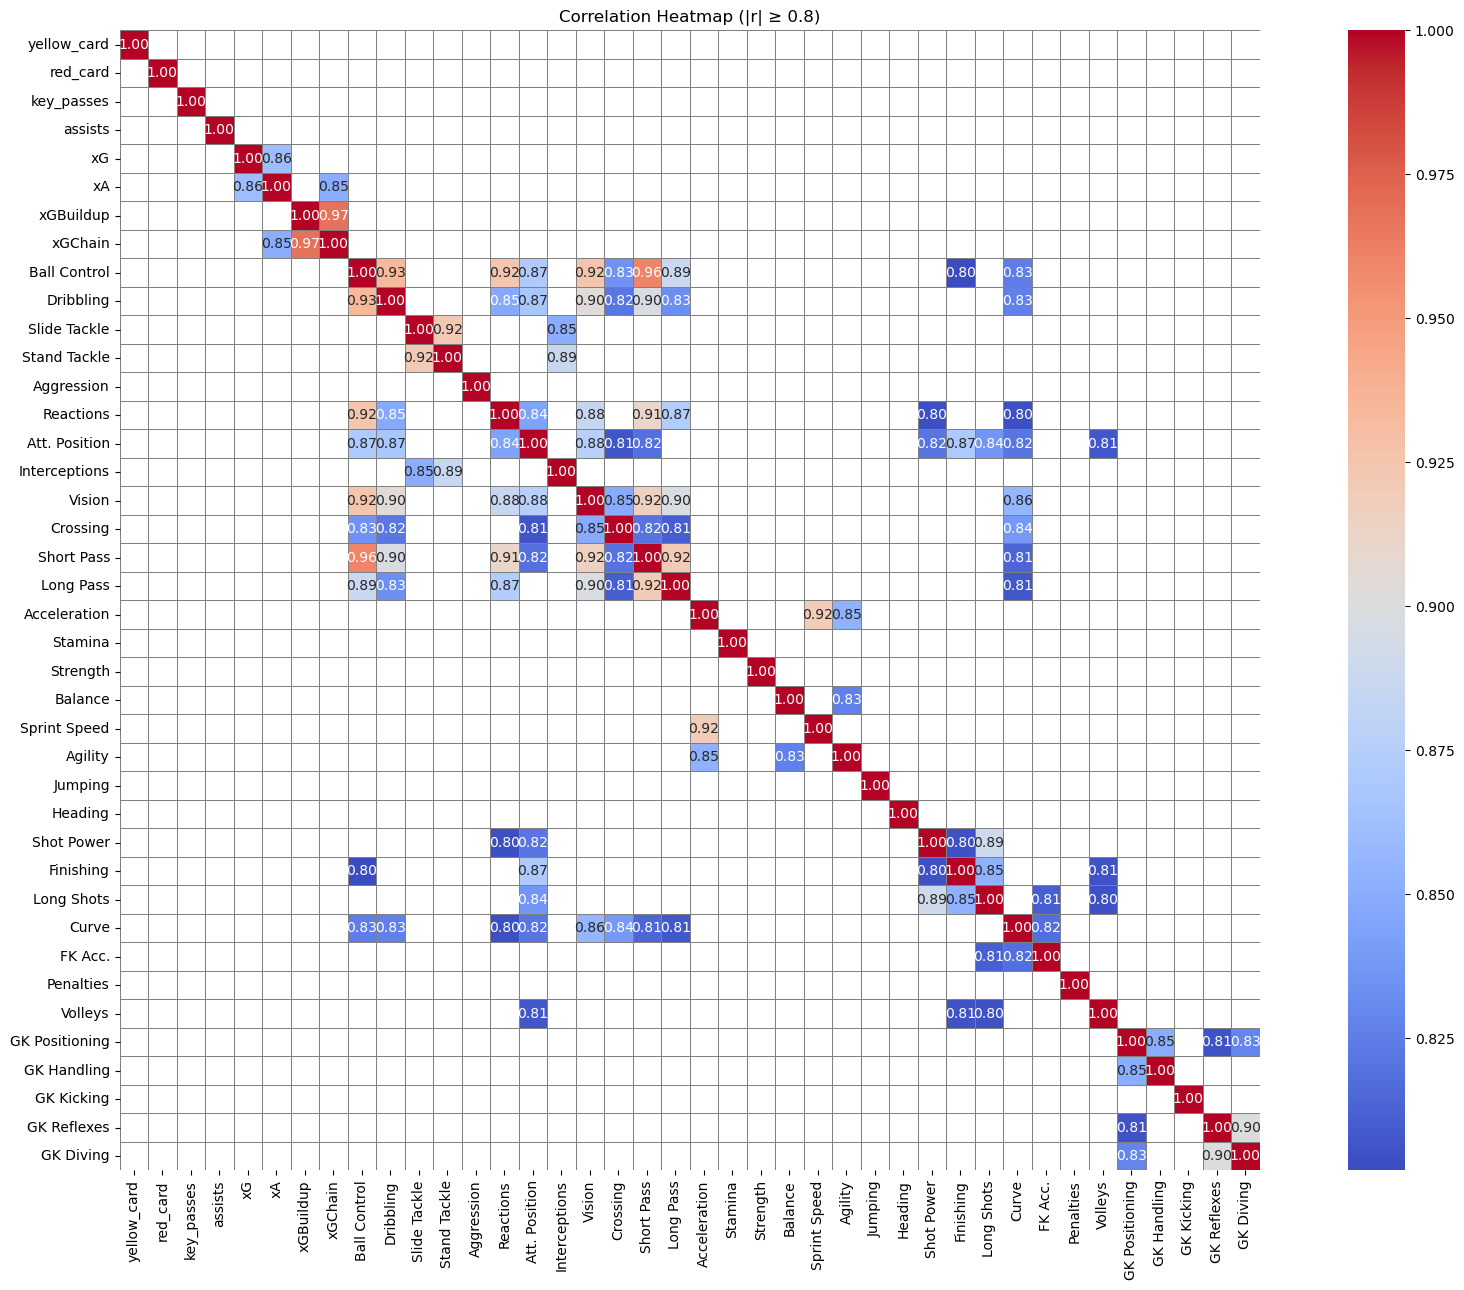

In [547]:
plot_correlation_matrix(merged_team_stats_df[stat_columns_list])

In [548]:
# Step 2: Pivot so that home and away stats become separate columns
pivot_df = merged_team_stats_df.pivot(index='id', columns='h_a')

# Step 3: Flatten MultiIndex columns (e.g., ('xG', 'h') → 'xG_h')
pivot_df.columns = [f"{col}_{side}" for col, side in pivot_df.columns]
pivot_df = pivot_df.reset_index()

# Step 4: Subtract away stats from home stats → stat_diff = home - away
diff_df = pd.DataFrame()
diff_df['id'] = pivot_df['id']

# Loop through stat_columns_list and compute difference
for col in stat_columns_list:
    h_col = f"{col}_h"
    a_col = f"{col}_a"
    diff_df[f"{col}"] = pivot_df[h_col] - pivot_df[a_col]

In [549]:
diff_df.columns

Index(['id', 'yellow_card', 'red_card', 'key_passes', 'assists', 'xG', 'xA',
       'xGBuildup', 'xGChain', 'Ball Control', 'Dribbling', 'Slide Tackle',
       'Stand Tackle', 'Aggression', 'Reactions', 'Att. Position',
       'Interceptions', 'Vision', 'Crossing', 'Short Pass', 'Long Pass',
       'Acceleration', 'Stamina', 'Strength', 'Balance', 'Sprint Speed',
       'Agility', 'Jumping', 'Heading', 'Shot Power', 'Finishing',
       'Long Shots', 'Curve', 'FK Acc.', 'Penalties', 'Volleys',
       'GK Positioning', 'GK Handling', 'GK Kicking', 'GK Reflexes',
       'GK Diving'],
      dtype='object')

In [550]:
player_stats_df=diff_df.copy()

In [551]:
diff_df

,id,yellow_card,red_card,key_passes,assists,xG,xA,xGBuildup,xGChain,Ball Control,...,Long Shots,Curve,FK Acc.,Penalties,Volleys,GK Positioning,GK Handling,GK Kicking,GK Reflexes,GK Diving
0,81,-1,0,-2,0,-0.048185,-0.301387,0.182611,-0.349043,2.621111,...,-5.634444,2.656667,-7.042222,-3.982222,4.362222,-6.0,-8.0,4.0,-2.0,-7.0
1,82,-1,0,5,-1,0.089876,-0.140721,0.434080,0.921305,-1.941111,...,-7.025556,-6.884444,-3.061111,-9.716667,-14.530000,-3.0,-2.0,4.0,3.0,4.0
2,83,-1,0,0,1,0.045769,0.130754,-0.537066,-0.933774,6.306144,...,3.325641,-3.470084,6.990712,10.306974,7.035808,4.0,11.0,13.0,0.0,-3.0
3,84,-2,0,9,0,1.107196,0.438657,-1.875367,-0.807215,-0.620000,...,-3.953333,-4.147778,-5.635556,-1.022222,-2.824444,-2.0,-3.0,17.0,4.0,5.0
4,85,1,0,2,-2,-0.978996,-1.634047,-7.855733,-8.832903,-5.846667,...,1.236667,6.711111,1.275556,5.502222,7.212222,0.0,-4.0,13.0,-1.0,-2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3415,22301,-2,0,13,-1,-1.710653,-0.466442,0.580999,-2.382747,3.503333,...,-3.007778,-5.827778,-2.648889,-0.094444,-4.334444,-8.0,-6.0,-1.0,0.0,-4.0
3416,22302,2,0,-4,-2,-2.455894,-2.274422,-6.441504,-9.646315,-5.761111,...,-6.335556,-3.275556,-8.226667,1.500000,-1.971111,-5.0,-5.0,-9.0,-2.0,-5.0
3417,22303,4,0,-22,-2,-3.085805,-1.636906,-7.773180,-11.612703,-15.157436,...,-18.216767,-16.838662,-22.722773,-9.362665,-15.314896,-12.0,-11.0,-18.0,-10.0,-11.0
3418,22304,-1,-1,8,-1,0.765949,0.107279,2.386318,3.010082,-1.105275,...,-4.341468,-7.469852,-3.721551,0.154170,-5.549716,-6.0,-2.0,-10.0,-3.0,-4.0


In [552]:
player_stats_df

,id,yellow_card,red_card,key_passes,assists,xG,xA,xGBuildup,xGChain,Ball Control,...,Long Shots,Curve,FK Acc.,Penalties,Volleys,GK Positioning,GK Handling,GK Kicking,GK Reflexes,GK Diving
0,81,-1,0,-2,0,-0.048185,-0.301387,0.182611,-0.349043,2.621111,...,-5.634444,2.656667,-7.042222,-3.982222,4.362222,-6.0,-8.0,4.0,-2.0,-7.0
1,82,-1,0,5,-1,0.089876,-0.140721,0.434080,0.921305,-1.941111,...,-7.025556,-6.884444,-3.061111,-9.716667,-14.530000,-3.0,-2.0,4.0,3.0,4.0
2,83,-1,0,0,1,0.045769,0.130754,-0.537066,-0.933774,6.306144,...,3.325641,-3.470084,6.990712,10.306974,7.035808,4.0,11.0,13.0,0.0,-3.0
3,84,-2,0,9,0,1.107196,0.438657,-1.875367,-0.807215,-0.620000,...,-3.953333,-4.147778,-5.635556,-1.022222,-2.824444,-2.0,-3.0,17.0,4.0,5.0
4,85,1,0,2,-2,-0.978996,-1.634047,-7.855733,-8.832903,-5.846667,...,1.236667,6.711111,1.275556,5.502222,7.212222,0.0,-4.0,13.0,-1.0,-2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3415,22301,-2,0,13,-1,-1.710653,-0.466442,0.580999,-2.382747,3.503333,...,-3.007778,-5.827778,-2.648889,-0.094444,-4.334444,-8.0,-6.0,-1.0,0.0,-4.0
3416,22302,2,0,-4,-2,-2.455894,-2.274422,-6.441504,-9.646315,-5.761111,...,-6.335556,-3.275556,-8.226667,1.500000,-1.971111,-5.0,-5.0,-9.0,-2.0,-5.0
3417,22303,4,0,-22,-2,-3.085805,-1.636906,-7.773180,-11.612703,-15.157436,...,-18.216767,-16.838662,-22.722773,-9.362665,-15.314896,-12.0,-11.0,-18.0,-10.0,-11.0
3418,22304,-1,-1,8,-1,0.765949,0.107279,2.386318,3.010082,-1.105275,...,-4.341468,-7.469852,-3.721551,0.154170,-5.549716,-6.0,-2.0,-10.0,-3.0,-4.0


In [553]:
player_stats_df.drop(columns=['xGChain'], inplace=True)
player_stats_df['GK_SaveAbility'] = (player_stats_df['GK Diving'] + player_stats_df['GK Reflexes']) / 2
player_stats_df = player_stats_df.drop(columns=['GK Diving', 'GK Reflexes'])
stat_columns_list.remove('xGChain')
stat_columns_list.remove('GK Diving')
stat_columns_list.remove('GK Reflexes')
stat_columns_list.append('GK_SaveAbility')


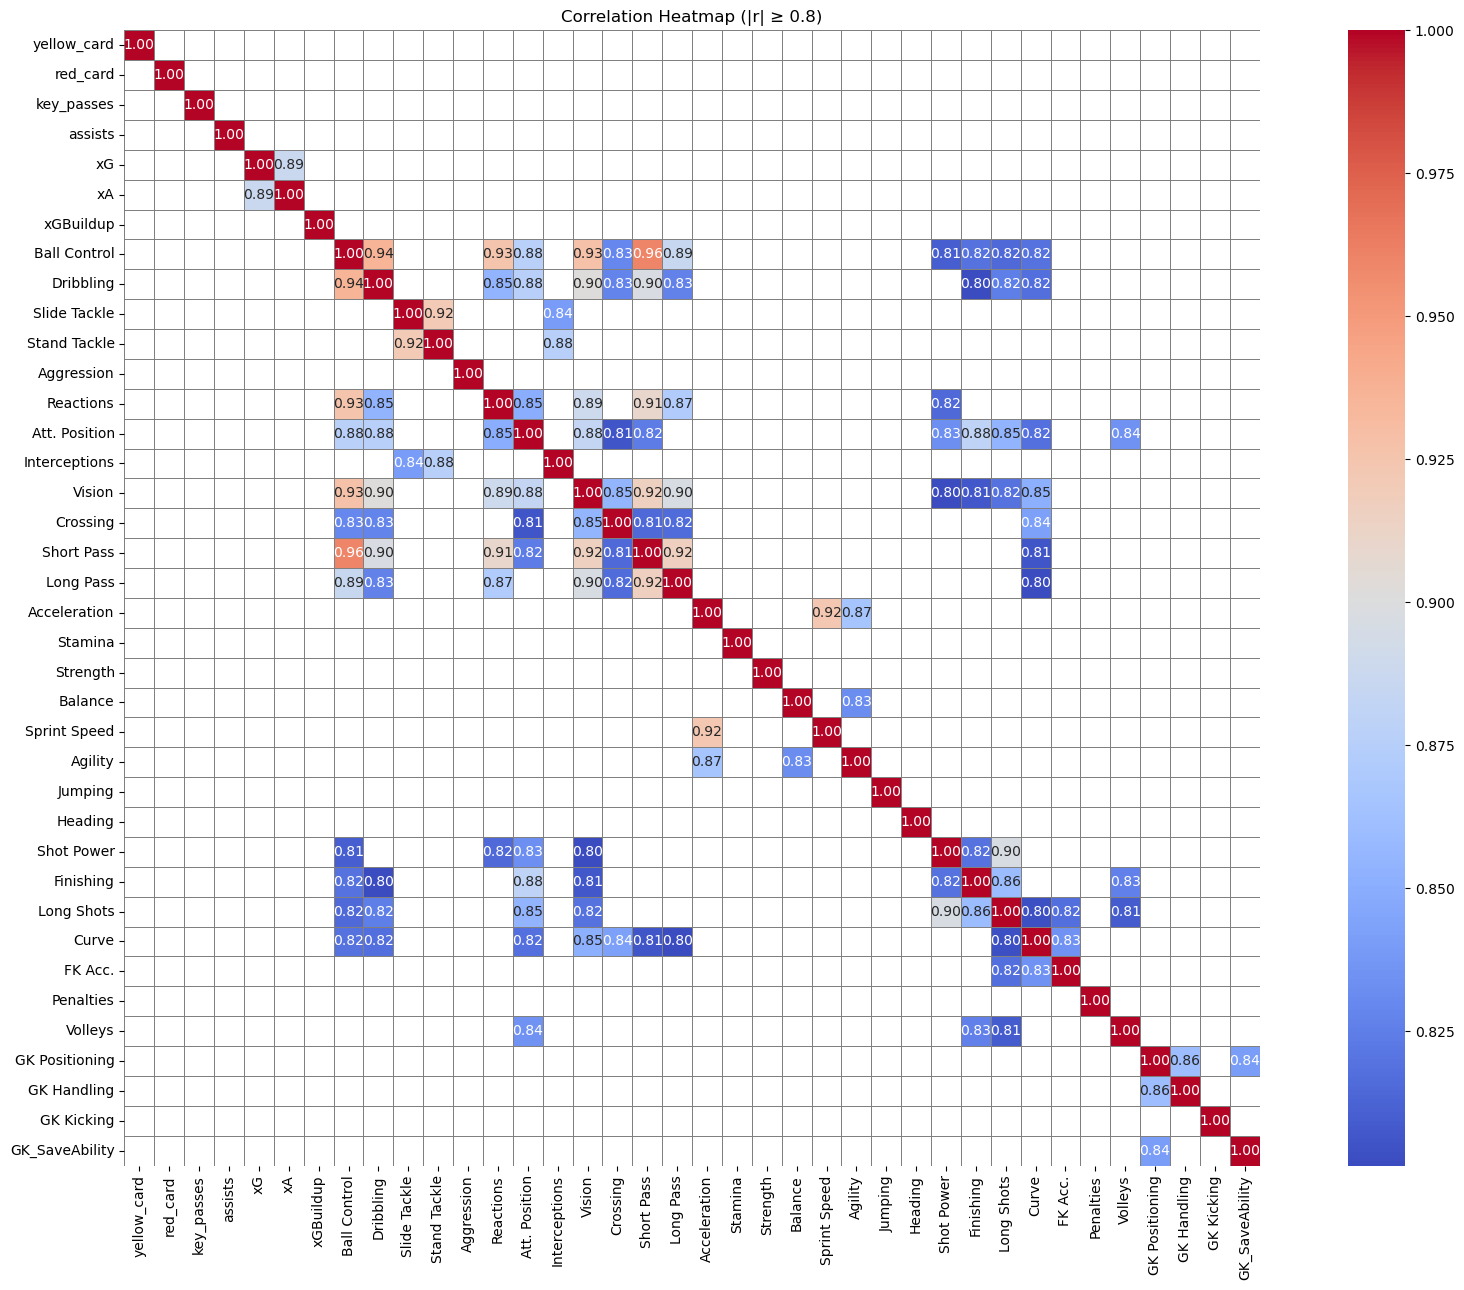

In [554]:
plot_correlation_matrix(player_stats_df[stat_columns_list])

In [555]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X = player_stats_df[stat_columns_list]
vif = pd.DataFrame()
vif['feature'] = X.columns
vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

In [556]:
vif.sort_values(by='VIF', ascending=False, inplace=True);vif.reset_index().drop(columns='index')

,feature,VIF
0,Ball Control,29.166256
1,Short Pass,20.655559
2,Dribbling,14.710357
3,Vision,14.388344
4,Reactions,13.622727
5,Acceleration,13.010649
6,Long Pass,11.731411
7,Att. Position,10.956197
8,Sprint Speed,10.814713
9,Stand Tackle,10.625484


In [557]:
player_stats_df["Overall Ball Skills"]= player_stats_df[["Dribbling", "Ball Control"]].mean(axis=1)
player_stats_df["Overall Passing"]= player_stats_df[["Short Pass", "Long Pass","Crossing"]].mean(axis=1)
player_stats_df["Overall Shooting"]= player_stats_df[["Finishing", "Shot Power", "Long Shots", "Heading", "Curve", "FK Acc.", "Penalties", "Volleys"]].mean(axis=1)
player_stats_df["Overall Defence"]= player_stats_df[["Stand Tackle", "Slide Tackle", "Interceptions"]].mean(axis=1)
player_stats_df["Overall Physical"]= player_stats_df[["Jumping", "Stamina", "Strength", "Acceleration","Agility", "Balance", "Sprint Speed"]].mean(axis=1)
player_stats_df["Overall Goalkeeper"]= player_stats_df[[ "GK Handling", "GK Kicking", "GK Positioning",  'GK_SaveAbility']].mean(axis=1)
player_stats_df["Overall Mental"]= player_stats_df[["Reactions", "Att. Position", "Vision", "Aggression"]].mean(axis=1)
player_stats_df["Overall"]= player_stats_df[["Overall Ball Skills", "Overall Passing", "Overall Shooting", "Overall Defence", "Overall Physical", "Overall Goalkeeper"]].mean(axis=1)

# Now lets normalize the corresponding columns by subtracting the overall stats from the individual stats






In [558]:
shooting_stats = ["Finishing", "Shot Power", "Long Shots", "Heading", "Curve", "FK Acc.", "Penalties", "Volleys"]
for stat in shooting_stats:
    player_stats_df[f"{stat}_adj"] = player_stats_df[stat] - player_stats_df["Overall Shooting"]
passing_stats = ["Short Pass", "Long Pass", "Crossing"]
for stat in passing_stats:
    player_stats_df[f"{stat}_adj"] = player_stats_df[stat] - player_stats_df["Overall Passing"]

defence_stats = ["Stand Tackle", "Slide Tackle", "Interceptions"]
for stat in defence_stats:
    player_stats_df[f"{stat}_adj"] = player_stats_df[stat] - player_stats_df["Overall Defence"]
physical_stats = ["Jumping", "Stamina", "Strength", "Acceleration", "Agility", "Balance", "Sprint Speed"]
for stat in physical_stats:
    player_stats_df[f"{stat}_adj"] = player_stats_df[stat] - player_stats_df["Overall Physical"]
goalkeeper_stats = ["GK Handling", "GK Kicking", "GK Positioning", "GK_SaveAbility"]
for stat in goalkeeper_stats:
    player_stats_df[f"{stat}_adj"] = player_stats_df[stat] - player_stats_df["Overall Goalkeeper"]
mental_stats = ["Reactions", "Att. Position", "Vision", "Aggression", "Dribbling"]
for stat in mental_stats:
    player_stats_df[f"{stat}_adj"] = player_stats_df[stat] - player_stats_df["Overall Mental"]
overall_stats = ["Overall Ball Skills", "Overall Passing", "Overall Shooting", "Overall Defence", "Overall Physical", "Overall Goalkeeper", "Overall Mental"]



for stat in overall_stats:
    player_stats_df[f"{stat}_adj"] = player_stats_df[stat] - player_stats_df["Overall"]

In [559]:
columns= shooting_stats + passing_stats + defence_stats + physical_stats + goalkeeper_stats + overall_stats + mental_stats + ["Ball Control"] + ["xA"]
updated_stats_df = player_stats_df.drop(columns=columns)

In [560]:
# Drop Overall Mental_adj to address collinearity
updated_stats_df = updated_stats_df.drop(columns=["Overall Mental_adj"])

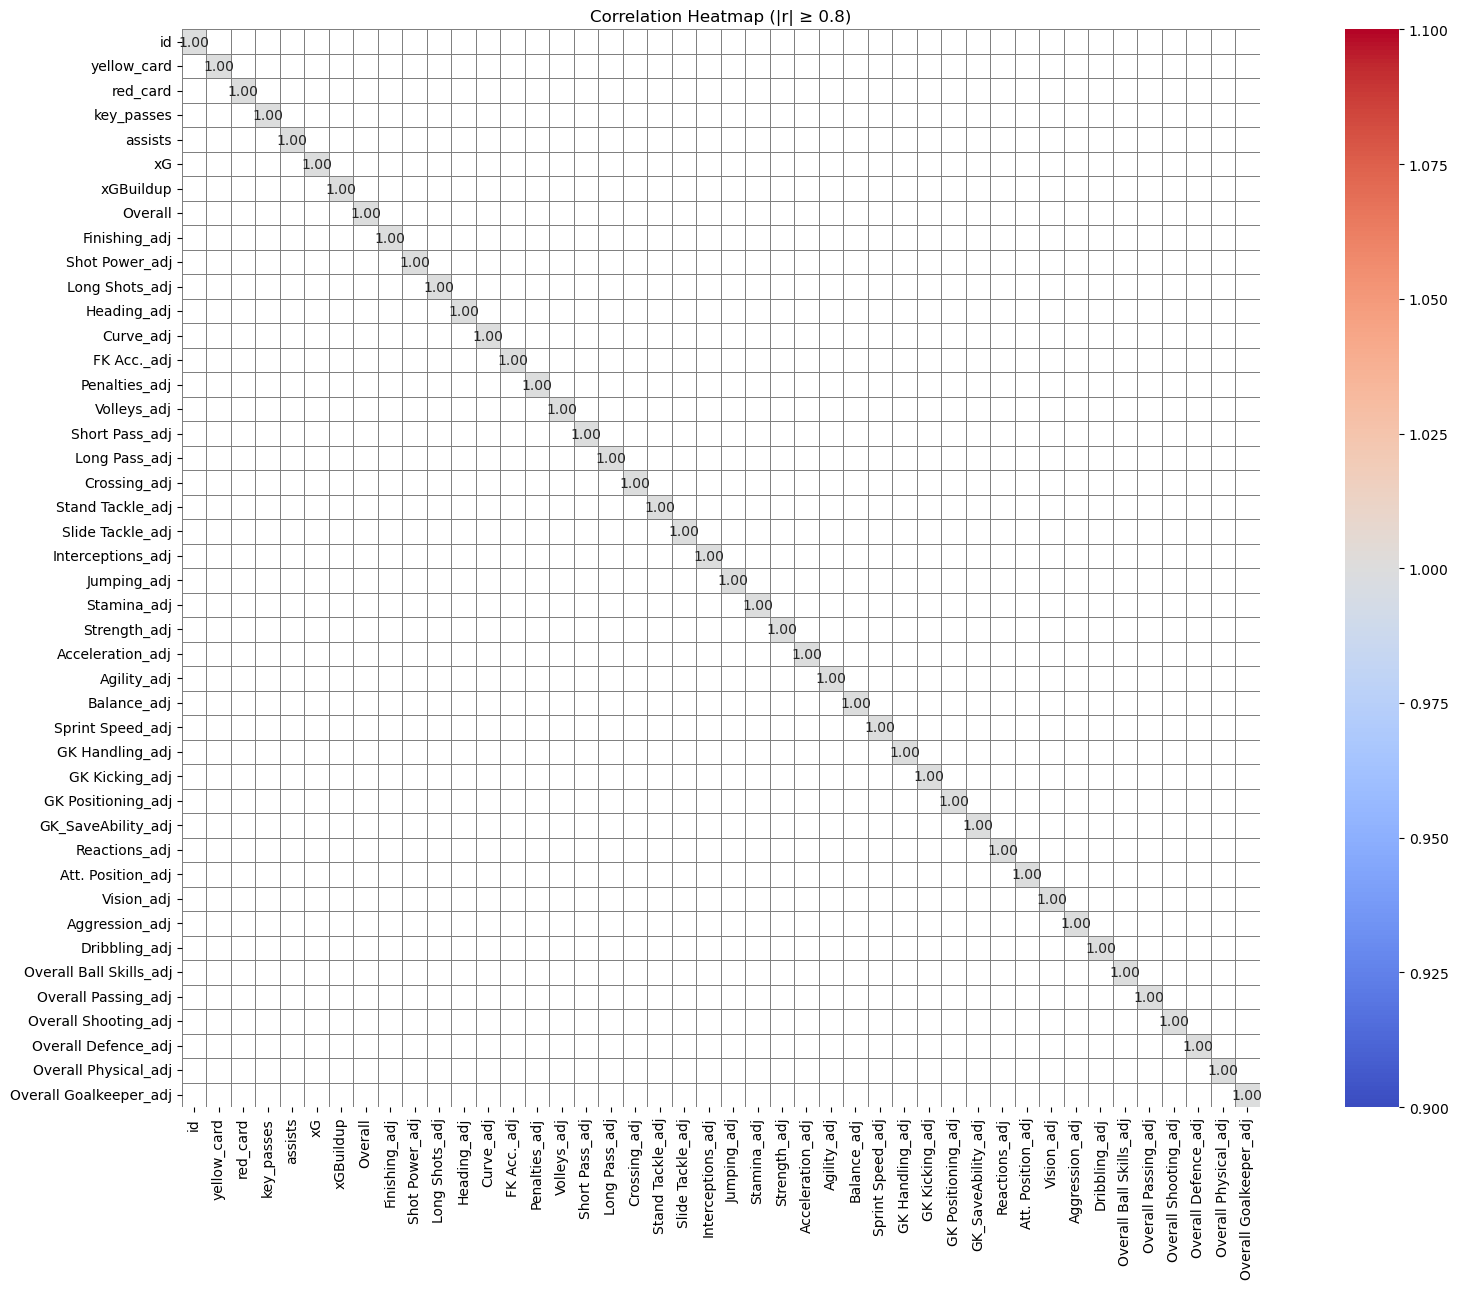

In [561]:
plot_correlation_matrix(updated_stats_df)

In [562]:

def perfectly_collinear_columns(df):
    X = df.select_dtypes(include=[np.number]).copy()
    X = X.loc[:, X.columns.notna()]  # safety
    # Drop all-NaN or single-valued columns up front (they're useless anyway)
    nunique = X.nunique(dropna=False)
    constant_cols = nunique[nunique <= 1].index.tolist()
    X = X.drop(columns=constant_cols, errors='ignore')

    full_rank = np.linalg.matrix_rank(X.values)
    redundant = []

    for col in X.columns:
        reduced = X.drop(columns=[col])
        reduced_rank = np.linalg.matrix_rank(reduced.values)
        # If removing `col` leaves the rank unchanged, `col` is redundant (collinear)
        if reduced_rank == full_rank:
            redundant.append(col)

    return redundant, constant_cols
redundant, constant_cols = perfectly_collinear_columns(updated_stats_df.drop(columns=['id']))
print("Redundant (perfectly collinear) columns:", redundant)
print("Constant/single-valued columns:", constant_cols)


Redundant (perfectly collinear) columns: ['Finishing_adj', 'Shot Power_adj', 'Long Shots_adj', 'Heading_adj', 'Curve_adj', 'FK Acc._adj', 'Penalties_adj', 'Volleys_adj', 'Short Pass_adj', 'Long Pass_adj', 'Crossing_adj', 'Stand Tackle_adj', 'Slide Tackle_adj', 'Interceptions_adj', 'Jumping_adj', 'Stamina_adj', 'Strength_adj', 'Acceleration_adj', 'Agility_adj', 'Balance_adj', 'Sprint Speed_adj', 'GK Handling_adj', 'GK Kicking_adj', 'GK Positioning_adj', 'GK_SaveAbility_adj', 'Reactions_adj', 'Att. Position_adj', 'Vision_adj', 'Aggression_adj', 'Overall Ball Skills_adj', 'Overall Passing_adj', 'Overall Shooting_adj', 'Overall Defence_adj', 'Overall Physical_adj', 'Overall Goalkeeper_adj']
Constant/single-valued columns: []


In [563]:
updated_stats_df.drop(columns=['Volleys_adj', 'Crossing_adj', 'Slide Tackle_adj', 'Sprint Speed_adj', 'GK_SaveAbility_adj', 'Aggression_adj', 'Overall Ball Skills_adj'], inplace=True)

In [564]:

redundant, constant_cols = perfectly_collinear_columns(updated_stats_df.drop(columns=['id']))
print("Redundant (perfectly collinear) columns:", redundant)
print("Constant/single-valued columns:", constant_cols)

Redundant (perfectly collinear) columns: []
Constant/single-valued columns: []


In [491]:
updated_stats_df

,id,yellow_card,red_card,key_passes,assists,xG,xGBuildup,Overall,Finishing_adj,Shot Power_adj,...,GK Positioning_adj,Reactions_adj,Att. Position_adj,Vision_adj,Dribbling_adj,Overall Ball Skills_adj,Overall Passing_adj,Overall Shooting_adj,Overall Defence_adj,Overall Physical_adj
0,81,-1,0,-2,0,-0.048185,0.182611,-0.181806,-1.530278,-5.656944,...,-2.375,2.710000,-1.097778,0.682222,0.774444,3.049028,1.262546,-2.969028,0.539954,1.560694
1,82,-1,0,5,-1,0.089876,0.434080,-3.016261,1.273889,-2.451667,...,-3.625,-0.110000,-1.668889,0.708889,2.723333,1.038483,-0.052998,-5.250961,0.230335,0.393880
2,83,-1,0,0,1,0.045769,-0.537066,4.545925,2.565967,-5.379140,...,-2.625,-0.029716,2.930002,2.377856,3.487822,2.373535,3.276502,-1.029880,-3.586234,-3.112997
3,84,-2,0,9,0,1.107196,-1.875367,-0.172082,6.077917,-1.112083,...,-6.125,-1.148889,2.170000,-0.545556,-0.235556,-0.305696,-1.130510,-2.620279,-0.596807,0.356209
4,85,1,0,2,-2,-0.978996,-7.855733,-0.289298,0.214306,1.706528,...,-1.875,0.965833,2.506944,3.358056,4.828056,-2.070147,-2.045147,3.097215,-2.447739,1.301520
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3415,22301,-2,0,13,-1,-1.710653,0.580999,-1.569570,5.642500,-4.814167,...,-3.750,0.137500,-1.584722,3.089722,5.597500,5.135126,1.034385,-1.764041,-2.449689,0.724649
3416,22302,2,0,-4,-2,-2.455894,-6.441504,-5.933161,3.246111,-2.271667,...,0.625,-1.133889,3.507222,0.447222,2.601667,0.661495,-0.054987,2.209272,-6.443135,3.319193
3417,22303,4,0,-22,-2,-3.085805,-7.773180,-13.403106,5.943979,-3.688818,...,0.875,-1.640728,0.111070,0.841290,-1.038935,-1.939552,-3.531776,-1.250073,-0.506653,6.699947
3418,22304,-1,-1,8,-1,0.765949,2.386318,-1.224992,-1.165149,2.003503,...,-0.625,-1.775414,-2.923036,-3.770754,-2.588577,-0.609810,-1.758375,-1.638913,10.008904,-1.851796


In [492]:
updated_stats_df.columns

Index(['id', 'yellow_card', 'red_card', 'key_passes', 'assists', 'xG',
       'xGBuildup', 'Overall', 'Finishing_adj', 'Shot Power_adj',
       'Long Shots_adj', 'Heading_adj', 'Curve_adj', 'FK Acc._adj',
       'Penalties_adj', 'Short Pass_adj', 'Long Pass_adj', 'Stand Tackle_adj',
       'Interceptions_adj', 'Jumping_adj', 'Stamina_adj', 'Strength_adj',
       'Acceleration_adj', 'Agility_adj', 'Balance_adj', 'GK Handling_adj',
       'GK Kicking_adj', 'GK Positioning_adj', 'Reactions_adj',
       'Att. Position_adj', 'Vision_adj', 'Dribbling_adj',
       'Overall Ball Skills_adj', 'Overall Passing_adj',
       'Overall Shooting_adj', 'Overall Defence_adj', 'Overall Physical_adj'],
      dtype='object')

In [565]:
updated_stats_df.to_csv('Data/fifa_stats_fully_processed.csv', index=False)

In [213]:
X = updated_stats_df
vif = pd.DataFrame()
vif['feature'] = X.columns
vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif.sort_values(by='VIF', ascending=False, inplace=True);vif.reset_index().drop(columns='index')

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,feature,VIF
0,Slide Tackle_adj,inf
1,Interceptions_adj,inf
2,Stamina_adj,inf
3,Strength_adj,inf
4,Acceleration_adj,inf
5,Agility_adj,inf
6,Balance_adj,inf
7,Sprint Speed_adj,inf
8,GK Handling_adj,inf
9,GK Kicking_adj,inf


In [186]:
player_stats_df.drop(columns=['Ball Control'], inplace=True)


In [188]:
stat_columns_list.remove('Ball Control')

In [ ]:
corr.to_csv('correlation_matrix.csv')

In [ ]:
player_stats_df["Player Name"].nunique()

2883